# 01 · Payment health EDA — where a UPI app leaks money and users

**Business context.** UPI apps earn almost nothing per P2P payment, so growth depends on
*trust* (payments that just work), *retention* (users who stay after the cashback), and
*loss control* (fraud and promo abuse). This notebook profiles 6 months of activity on a
fictional UPI app (**316k transactions, 12.4k users, 8 partner banks**) and quantifies
six known weak spots:

| # | Loophole | Question |
|---|---|---|
| 1 | Bank-side failures | Which remitter banks / hours cause technical declines? |
| 2 | Stuck refunds | How often do "debited but failed" refunds break the T+1 rule? |
| 3 | Leaky acquisition | Do cashback-acquired users stick around? |
| 4 | Fraud | Who gets defrauded, and do the current rules catch it? |
| 5 | Promo abuse | How much cashback goes to device farms? |
| 6 | Grievance redressal | How does resolution time affect CSAT? |

> Data is synthetic (see `data/generate_data.py`), modelled on publicly reported UPI pain points.

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import plot_style as ps
from features import load, TECH
ps.apply()
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
d = load()
tx, users, refunds, tickets, banks = d['tx'], d['users'], d['refunds'], d['tickets'], d['banks']
tx['is_tech_fail'] = tx.failure_reason.isin(TECH).astype(int)
tx['hour'] = tx.ts.dt.hour
END = pd.Timestamp('2026-06-30')

## 0 · Data quality checks
Before any analysis: completeness, uniqueness, validity, consistency and referential integrity.

In [2]:
checks = {
    'duplicate txn_id': tx.txn_id.duplicated().sum(),
    'txn with unknown user_id': (~tx.user_id.isin(users.user_id)).sum(),
    'FAILED without failure_reason': ((tx.status == 'FAILED') & tx.failure_reason.isna()).sum(),
    'SUCCESS with a failure_reason': ((tx.status == 'SUCCESS') & tx.failure_reason.notna()).sum(),
    'non-positive amount': (tx.amount <= 0).sum(),
    'amount above UPI limit (Rs 1 lakh)': (tx.amount > 100000).sum(),
    'txn before payer signup': (tx.ts < tx.user_id.map(users.set_index('user_id').signup_ts)).sum(),
    'refund for a non-failed txn': (~refunds.txn_id.isin(tx.loc[tx.status == 'FAILED', 'txn_id'])).sum(),
    'cashback on a failed txn': ((tx.cashback_inr > 0) & (tx.status != 'SUCCESS')).sum(),
}
pd.Series(checks, name='rows failing').to_frame()

,rows failing
duplicate txn_id,0
txn with unknown user_id,0
FAILED without failure_reason,0
SUCCESS with a failure_reason,0
non-positive amount,0
amount above UPI limit (Rs 1 lakh),0
txn before payer signup,0
refund for a non-failed txn,0
cashback on a failed txn,0


In [3]:
print('Null share by column (transactions):')
tx.isna().mean().loc[lambda s: s > 0].round(3)

Null share by column (transactions):


failure_reason   0.95
dtype: float64

Only expected nulls: `failure_reason` is null for successful payments. All integrity checks pass, so we can proceed.

## Headline KPIs

In [4]:
m = (tx.assign(month=tx.ts.dt.to_period('M'))
       .groupby('month')
       .agg(attempts=('txn_id', 'size'),
            success_rate=('status', lambda s: (s == 'SUCCESS').mean() * 100),
            gmv_lakh=('amount', lambda s: s[tx.loc[s.index, 'status'] == 'SUCCESS'].sum() / 1e5),
            mau=('user_id', 'nunique'),
            cashback=('cashback_inr', 'sum')))
m

,attempts,success_rate,gmv_lakh,mau,cashback
month,,,,,
2026-01,15017,95.56,106.48,2581,"42,150.00"
2026-02,33643,95.42,253.14,4647,"46,550.00"
2026-03,48390,95.54,376.03,5551,0.00
2026-04,66184,95.54,505.87,8123,"94,300.00"
2026-05,79549,95.54,635.60,8679,"6,209.00"
2026-06,73039,95.51,584.69,7393,0.00


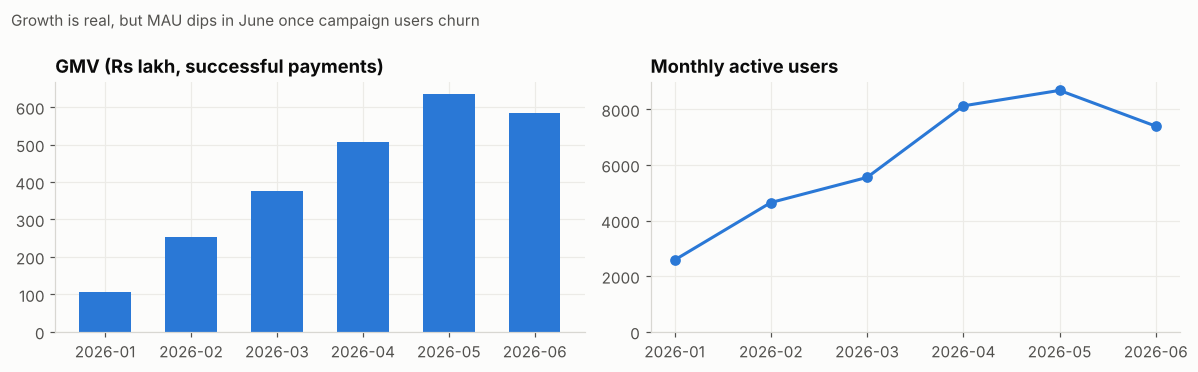

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
x = m.index.astype(str)
ax[0].bar(x, m.gmv_lakh, color=ps.BLUE, width=0.6)
ax[0].set_title('GMV (Rs lakh, successful payments)')
ax[1].plot(x, m.mau, color=ps.BLUE, marker='o', markersize=6)
ax[1].set_title('Monthly active users')
ax[1].set_ylim(0)
for a in ax: a.tick_params(axis='x', rotation=0)
fig.suptitle('Growth is real, but MAU dips in June once campaign users churn', x=0.01, ha='left', fontsize=10, color=ps.INK2)
fig.tight_layout(); ps.save(fig, '01_kpis');

## Loophole 1 · Technical declines are concentrated in three banks and the evening peak
Business declines (wrong PIN, low balance) belong to the user; **technical declines (bank server
down, timeout, network) are the platform's problem**. Each one is a payment the user blames on the app.

3 worst banks = 25% of traffic but 47% of technical declines


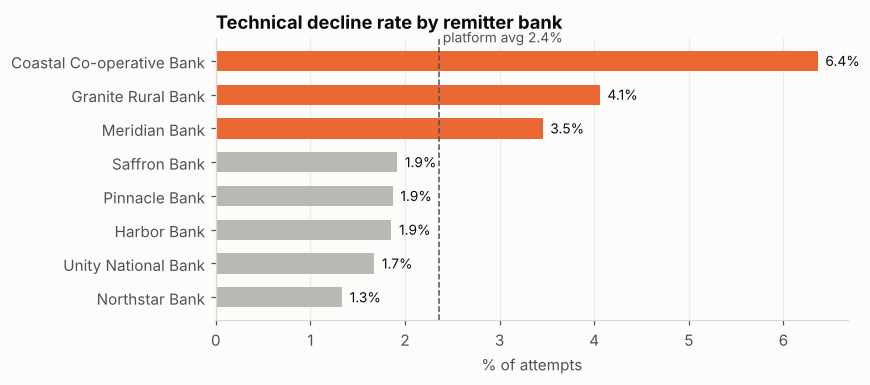

In [6]:
b = (tx.groupby('payer_bank').agg(attempts=('txn_id', 'size'), tech_fail_pct=('is_tech_fail', 'mean'))
       .assign(tech_fail_pct=lambda d: d.tech_fail_pct * 100)
       .join(banks.set_index('bank_code').bank_name)
       .sort_values('tech_fail_pct'))
avg = tx.is_tech_fail.mean() * 100
worst = b.tech_fail_pct.nlargest(3).index
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(b.bank_name, b.tech_fail_pct, color=[ps.ORANGE if i in worst else ps.GREY for i in b.index], height=0.6)
ax.axvline(avg, color=ps.INK2, lw=1, ls='--'); ax.text(avg, len(b) - 0.45, f' platform avg {avg:.1f}%', color=ps.INK2, fontsize=9)
for i, v in enumerate(b.tech_fail_pct): ax.text(v + 0.08, i, f'{v:.1f}%', va='center', fontsize=9)
ax.set_title('Technical decline rate by remitter bank'); ax.set_xlabel('% of attempts'); ax.grid(axis='y', visible=False)
fig.tight_layout(); ps.save(fig, '02_bank_declines');
share = tx[tx.payer_bank.isin(worst)].is_tech_fail.sum() / tx.is_tech_fail.sum()
print(f'3 worst banks = {tx.payer_bank.isin(worst).mean():.0%} of traffic but {share:.0%} of technical declines')

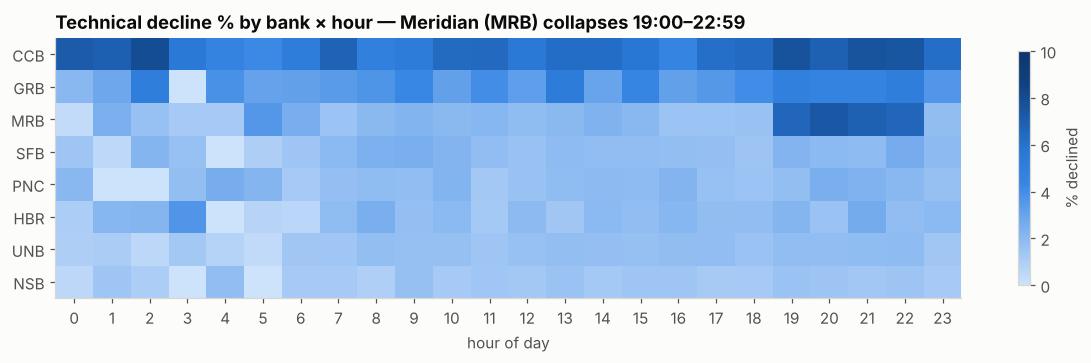

In [7]:
hm = tx.pivot_table(index='payer_bank', columns='hour', values='is_tech_fail', aggfunc='mean') * 100
hm = hm.loc[b.index[::-1]]
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('seq', ps.SEQ_BLUE)
fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(hm.values, aspect='auto', cmap=cmap, vmin=0, vmax=10)
ax.set_yticks(range(len(hm)), hm.index); ax.set_xticks(range(24), range(24)); ax.grid(False)
ax.set_xlabel('hour of day'); ax.set_title('Technical decline % by bank × hour — Meridian (MRB) collapses 19:00–22:59')
fig.colorbar(im, ax=ax, label='% declined', shrink=0.9)
fig.tight_layout(); ps.save(fig, '03_bank_hour_heatmap');

In [8]:
# Does the user recover by retrying? (same payee, success within 30 min)
f = tx[tx.is_tech_fail == 1][['txn_id', 'user_id', 'payee_id', 'ts', 'amount']]
s = tx[tx.status == 'SUCCESS'][['user_id', 'payee_id', 'ts']].rename(columns={'ts': 'ts_ok'})
j = f.merge(s, on=['user_id', 'payee_id'])
j = j[(j.ts_ok > j.ts) & (j.ts_ok <= j.ts + pd.Timedelta(minutes=30))]
recovered = f.txn_id.isin(j.txn_id)
print(f'Technical declines: {len(f):,} | recovered by retry: {recovered.mean():.0%} | '
      f'abandoned GMV: Rs {f.loc[~recovered, "amount"].sum()/1e5:.1f} lakh in 6 months')

Technical declines: 7,450 | recovered by retry: 51% | abandoned GMV: Rs 31.4 lakh in 6 months


## Loophole 2 · "Money debited, payment failed" — refunds that break T+1
Under RBI's TAT framework a failed UPI debit must be auto-reversed by **T+1**; beyond that the
customer is owed **Rs 100/day**. These cases also drive most support tickets.

Breach rate overall: 14.6% | compensation liability: Rs 95,900


,refunds,breach_pct,p90_tat_h,compensation_inr
payer_bank,,,,
CCB,506,30.43,88.00,42900
MRB,451,27.72,77.50,34200
GRB,218,23.85,76.62,15300
SFB,298,3.02,15.20,900
HBR,195,2.56,14.76,500
PNC,134,2.24,13.22,300
NSB,332,1.81,13.36,800
UNB,336,1.79,13.35,1000


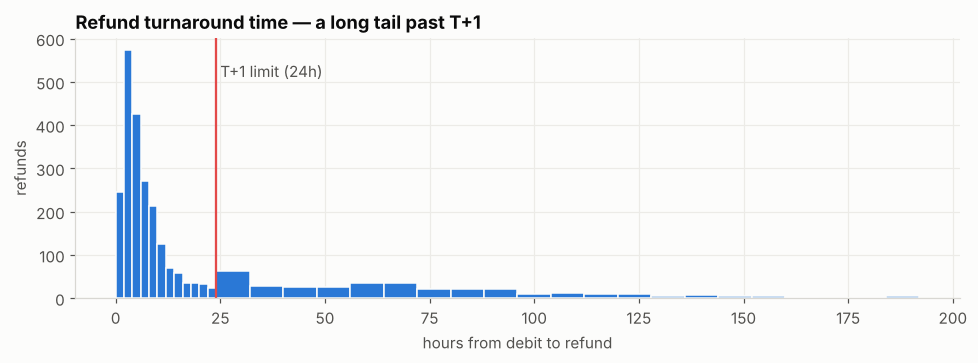

In [9]:
r = refunds.merge(tx[['txn_id', 'payer_bank']], on='txn_id')
fig, ax = plt.subplots(figsize=(9, 3.4))
bins = np.r_[0:24:2, 24:192:8, 400]
ax.hist(r.tat_hours.clip(upper=199), bins=np.r_[0:24:2, 24:200:8], color=ps.BLUE, edgecolor='#fcfcfb', linewidth=1)
ax.axvline(24, color=ps.RED, lw=1.5); ax.text(25, ax.get_ylim()[1]*0.85, 'T+1 limit (24h)', color=ps.INK2)
ax.set_xlabel('hours from debit to refund'); ax.set_ylabel('refunds'); ax.set_title('Refund turnaround time — a long tail past T+1')
fig.tight_layout(); ps.save(fig, '04_refund_tat');
rb = (r.groupby('payer_bank').agg(refunds=('refund_id', 'size'), breach_pct=('tat_hours', lambda s: (s > 24).mean() * 100),
                                 p90_tat_h=('tat_hours', lambda s: s.quantile(.9)), compensation_inr=('compensation_due_inr', 'sum'))
        .sort_values('breach_pct', ascending=False))
print(f"Breach rate overall: {(r.tat_hours > 24).mean():.1%} | compensation liability: Rs {r.compensation_due_inr.sum():,.0f}")
rb

## Loophole 3 · Cashback buys installs, not users

,users,churn_pct,median_txns
acquisition_channel,,,
referral,1916,30.90,23.00
organic,4641,33.76,22.00
cashback_campaign,3900,65.46,8.00


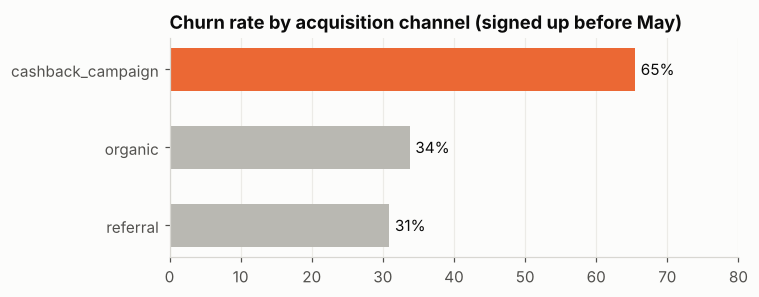

In [10]:
last = tx.groupby('user_id').ts.max()
u = users.set_index('user_id').assign(last_ts=last, n_txn=tx.groupby('user_id').size())
u['churned'] = (END - u.last_ts).dt.total_seconds() / 86400 > 30   # same definition as sql/04
mature = u[u.signup_ts < '2026-04-30']
ch = mature.groupby('acquisition_channel').agg(users=('churned', 'size'), churn_pct=('churned', 'mean'),
                                              median_txns=('n_txn', 'median'))
ch['churn_pct'] *= 100
fig, ax = plt.subplots(figsize=(7, 2.8))
ch = ch.sort_values('churn_pct')
ax.barh(ch.index, ch.churn_pct, color=[ps.ORANGE if i == 'cashback_campaign' else ps.GREY for i in ch.index], height=0.55)
for i, v in enumerate(ch.churn_pct): ax.text(v + 0.8, i, f'{v:.0f}%', va='center')
ax.set_xlim(0, 80); ax.set_title('Churn rate by acquisition channel (signed up before May)'); ax.grid(axis='y', visible=False)
fig.tight_layout(); ps.save(fig, '05_churn_by_channel');
ch

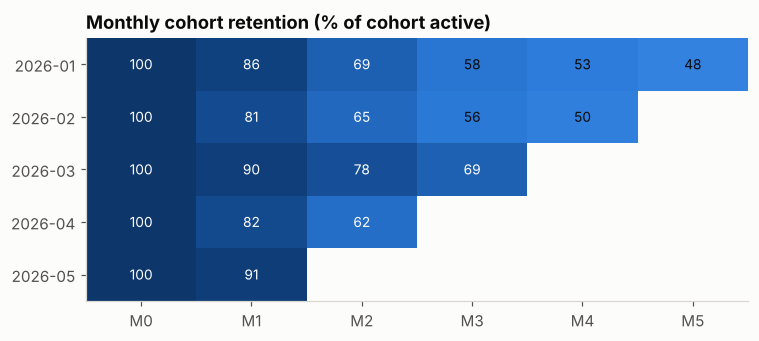

In [11]:
# monthly cohort retention
a = tx.merge(users[['user_id', 'signup_ts']], on='user_id')
a['cohort'] = a.signup_ts.dt.to_period('M'); a['m'] = (a.ts.dt.to_period('M') - a.cohort).apply(lambda x: x.n)
coh = a.groupby(['cohort', 'm']).user_id.nunique().unstack()
ret = coh.div(coh[0], axis=0) * 100
for c in ret.index:  # blank out months that haven't happened yet
    ret.loc[c, [k for k in ret.columns if (c + k) > pd.Period('2026-06', 'M')]] = np.nan
fig, ax = plt.subplots(figsize=(7, 3.2))
im = ax.imshow(ret.values, cmap=cmap, vmin=0, vmax=100, aspect='auto')
for i in range(ret.shape[0]):
    for k in range(ret.shape[1]):
        v = ret.values[i, k]
        if not np.isnan(v): ax.text(k, i, f'{v:.0f}', ha='center', va='center', fontsize=9, color='white' if v > 60 else ps.INK)
ax.set_xticks(range(ret.shape[1]), [f'M{k}' for k in ret.columns]); ax.set_yticks(range(len(ret)), ret.index.astype(str))
ax.grid(False); ax.set_title('Monthly cohort retention (% of cohort active)')
fig.tight_layout(); ps.save(fig, '06_cohort_retention');

In [12]:
# Does a bad first two weeks predict churn?
early = (tx.merge(users[['user_id', 'signup_ts']], on='user_id')
           .assign(early=lambda d: (d.is_tech_fail == 1) & ((d.ts - d.signup_ts).dt.total_seconds() / 86400 <= 14))
           .groupby('user_id').early.max())
mature = mature.assign(early_fail=early)
print((mature.groupby('early_fail').churned.mean() * 100).round(1).rename('churn %'))

early_fail
False   44.00
True    53.70
Name: churn %, dtype: float64


## Loophole 4 · Fraud targets older users through collect requests, and the rules miss it

Fraud loss (successful fraud): Rs 31.8 lakh
Legacy rules: blocked 428 | precision 31% | recall 18%


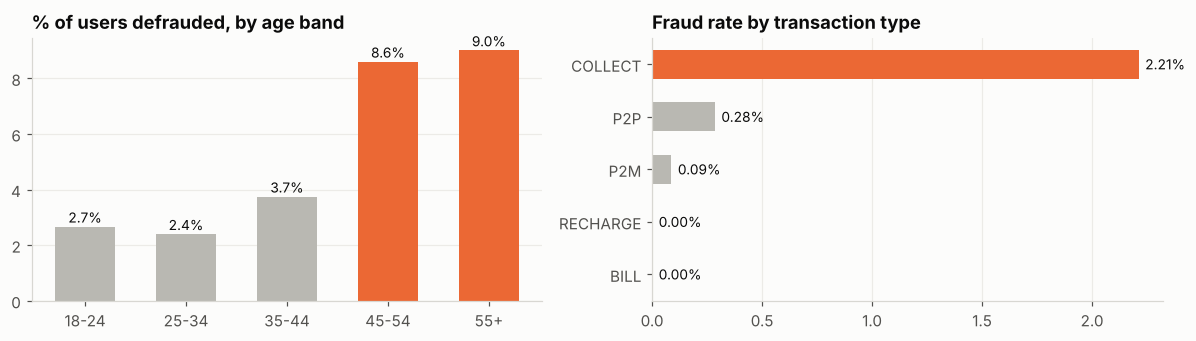

In [13]:
vic = tx[tx.is_fraud == 1].user_id.unique()
ab = users.assign(victim=users.user_id.isin(vic)).groupby('age_band').victim.mean() * 100
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].bar(ab.index, ab.values, color=[ps.ORANGE if a in ('45-54', '55+') else ps.GREY for a in ab.index], width=0.6)
for i, v in enumerate(ab.values): ax[0].text(i, v + 0.15, f'{v:.1f}%', ha='center', fontsize=9)
ax[0].set_title('% of users defrauded, by age band'); ax[0].grid(axis='x', visible=False)
ft = tx.groupby('txn_type').is_fraud.mean().mul(100).sort_values()
ax[1].barh(ft.index, ft.values, color=[ps.ORANGE if t == 'COLLECT' else ps.GREY for t in ft.index], height=0.55)
for i, v in enumerate(ft.values): ax[1].text(v + 0.03, i, f'{v:.2f}%', va='center', fontsize=9)
ax[1].set_title('Fraud rate by transaction type'); ax[1].grid(axis='y', visible=False)
fig.tight_layout(); ps.save(fig, '07_fraud_profile');
blocked = tx.failure_reason == 'RISK_BLOCKED'
print(f"Fraud loss (successful fraud): Rs {tx.loc[(tx.is_fraud==1)&(tx.status=='SUCCESS'),'amount'].sum()/1e5:.1f} lakh")
print(f"Legacy rules: blocked {blocked.sum()} | precision {tx[blocked].is_fraud.mean():.0%} | recall {blocked[tx.is_fraud==1].mean():.0%}")

## Loophole 5 · Device farms farming sign-up cashback

In [14]:
dev = users.groupby('device_id').agg(accounts=('user_id', 'size'), first=('signup_ts', 'min'), last=('signup_ts', 'max'))
dev['span_h'] = (dev['last'] - dev['first']).dt.total_seconds() / 3600
cb = tx[['user_id', 'cashback_inr']].merge(users[['user_id', 'device_id']], on='user_id').groupby('device_id').cashback_inr.sum()
dev = dev.join(cb.rename('cashback_inr'))
farms = dev[dev.accounts >= 3].sort_values('cashback_inr', ascending=False)
print(f'{len(farms)} devices with >=3 accounts ({farms.accounts.sum()} accounts, all created within {farms.span_h.max():.0f}h of each other)')
print(f'Cashback extracted: Rs {farms.cashback_inr.sum():,.0f} = {farms.cashback_inr.sum()/tx.cashback_inr.sum():.1%} of all cashback')
farms.head(8)

42 devices with >=3 accounts (324 accounts, all created within 9h of each other)
Cashback extracted: Rs 20,489 = 10.8% of all cashback


,accounts,first,last,span_h,cashback_inr
device_id,,,,,
D0078022,10,2026-04-07 05:09:57,2026-04-07 13:50:57,8.68,807.00
D0046488,10,2026-04-23 19:24:07,2026-04-24 03:52:07,8.47,761.00
D0042223,9,2026-04-15 06:03:26,2026-04-15 14:29:26,8.43,711.00
D0081285,9,2026-04-06 01:30:48,2026-04-06 10:49:48,9.32,711.00
D0050869,9,2026-04-03 00:19:59,2026-04-03 08:08:59,7.82,701.00
D0079034,9,2026-04-20 08:38:42,2026-04-20 14:06:42,5.47,694.00
D0085849,9,2026-04-19 01:28:35,2026-04-19 10:33:35,9.08,682.00
D0099252,8,2026-04-18 15:16:14,2026-04-18 22:52:14,7.60,670.00


## Loophole 6 · Slow grievance redressal destroys satisfaction

category
REFUND_NOT_RECEIVED      1245
CASHBACK_NOT_RECEIVED     338
FRAUD_REPORT              310
APP_BUG                   212
OTHER                     168
KYC_ISSUE                 166
PAYMENT_BLOCKED           136
Name: tickets, dtype: int64


,tickets,avg_csat,detractor_pct
bucket,,,
<=12h,487,4.32,0.00
12-48h,788,3.99,2.41
2-5 days,250,2.68,41.20
>5 days,144,1.17,97.92


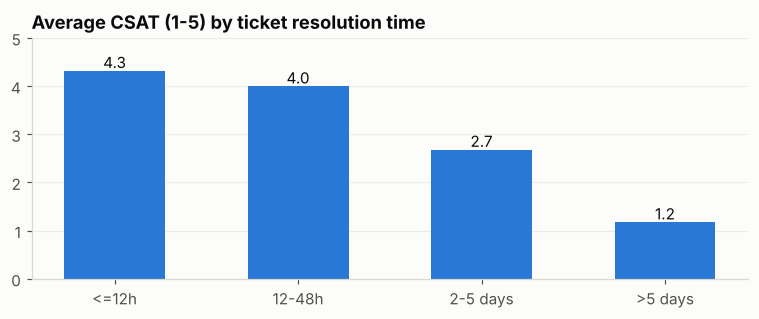

In [15]:
t = tickets.dropna(subset=['resolved_ts', 'csat']).copy()
t['res_h'] = (t.resolved_ts - t.created_ts).dt.total_seconds() / 3600
t['bucket'] = pd.cut(t.res_h, [0, 12, 48, 120, 1e4], labels=['<=12h', '12-48h', '2-5 days', '>5 days'])
cs = t.groupby('bucket', observed=True).agg(tickets=('ticket_id', 'size'), avg_csat=('csat', 'mean'),
                                          detractor_pct=('csat', lambda s: (s <= 2).mean() * 100))
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(cs.index.astype(str), cs.avg_csat, color=ps.BLUE, width=0.55)
for i, v in enumerate(cs.avg_csat): ax.text(i, v + 0.06, f'{v:.1f}', ha='center')
ax.set_ylim(0, 5); ax.set_title('Average CSAT (1-5) by ticket resolution time'); ax.grid(axis='x', visible=False)
fig.tight_layout(); ps.save(fig, '08_csat_vs_resolution');
print(tickets.groupby('category').size().sort_values(ascending=False).rename('tickets'))
cs

## Summary
1. **Three banks (25% of traffic) cause 47% of technical declines**; one of them degrades mainly at peak hours, a routing / bank-switch nudge problem.
2. **Roughly half of users abandon after a technical decline** instead of retrying, which is lost GMV.
3. **~1 in 7 debited-but-failed refunds miss T+1**, and the same three banks own almost all the compensation liability.
4. **Cashback-acquired users churn at roughly twice the rate** of organic/referral users; a failure in week one adds more churn on top.
5. **Collect-request scams on 45+ users** are the biggest fraud vector; legacy rules catch < 1 in 5 frauds while wrongly blocking more than 2 legit payments for every fraud caught → see notebook 02.
6. **~10% of cashback is extracted by device farms** detectable with a simple device-graph rule.
7. **Tickets resolved after 5 days have CSAT ≈ 1**, with fraud reports the slowest category.